In [1]:
import warnings, random, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import t as t_dist
from IPython.display import display
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict)
from sklearn.metrics import (make_scorer, f1_score, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

N = 2                     
SEED = 42 + N            
np.random.seed(SEED)
random.seed(SEED)

FAST_MODE = False       

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print(f"SEED = {SEED}, FAST_MODE = {FAST_MODE}")

p:\lnu\7.0\machine-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SEED = 44, FAST_MODE = False


# Блок 1. EDA

In [2]:
# ---------- 1.1 Завантаження даних, category -> object ----------
anneal = fetch_openml(name="anneal", version=1, as_frame=True, parser="auto")
X_raw = anneal.data.copy()
from urllib.parse import unquote
X_raw.columns = [unquote(str(c)) for c in X_raw.columns]
y_raw = anneal.target.astype(str).copy()

for c in X_raw.select_dtypes(include="category").columns:
    X_raw[c] = X_raw[c].astype(object).where(X_raw[c].notna(), np.nan)

print("Завантажено:", X_raw.shape, "| цільова:", y_raw.name)


Завантажено: (898, 38) | цільова: class


In [3]:
# ---------- 1.2 Розмір і типи ознак ----------
print("Розмір X:", X_raw.shape)
print("\nКількість ознак за типами:")
display(X_raw.dtypes.astype(str).value_counts().rename("n_features").to_frame())

types_df = pd.DataFrame({
    "dtype": X_raw.dtypes.astype(str),
    "n_unique": X_raw.nunique(dropna=True),
})
display(types_df.T)

Розмір X: (898, 38)

Кількість ознак за типами:


,n_features
object,32
int64,4
float64,2


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,surface-finish,surface-quality,enamelability,bc,bf,bt,bw/me,bl,m,chrom,phos,cbond,marvi,exptl,ferro,corr,blue/bright/varn/clean,lustre,jurofm,s,p,shape,thick,width,len,oil,bore,packing
dtype,object,object,object,int64,int64,object,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,float64,float64,int64,object,object,object
n_unique,2,1,7,10,7,1,2,4,8,1,1,4,2,1,1,1,2,1,0,1,1,1,0,1,1,0,3,1,0,0,0,2,50,68,24,2,3,2


 Датасет Annealing (OpenML, `anneal`, версія 1) містить 898 спостережень і 38 вихідних ознак: 32 типу `object`, 4 `int64` і 2 `float64`. Більшість ознак категоріальні, а за числових лише кілька (`carbon`, `hardness`, `strength`, `thick`, `width`, `len`). Частина ознак має 0 або 1 унікальне значення, тобто вони порожні або константні й не несуть інформації для класифікації.

,n_missing,frac_missing,dtype
p,898,1.000,object
s,898,1.000,object
jurofm,898,1.000,object
corr,898,1.000,object
marvi,898,1.000,object
m,898,1.000,object
bc,897,0.999,object
exptl,896,0.998,object
blue/bright/varn/clean,892,0.993,object
phos,891,0.992,object


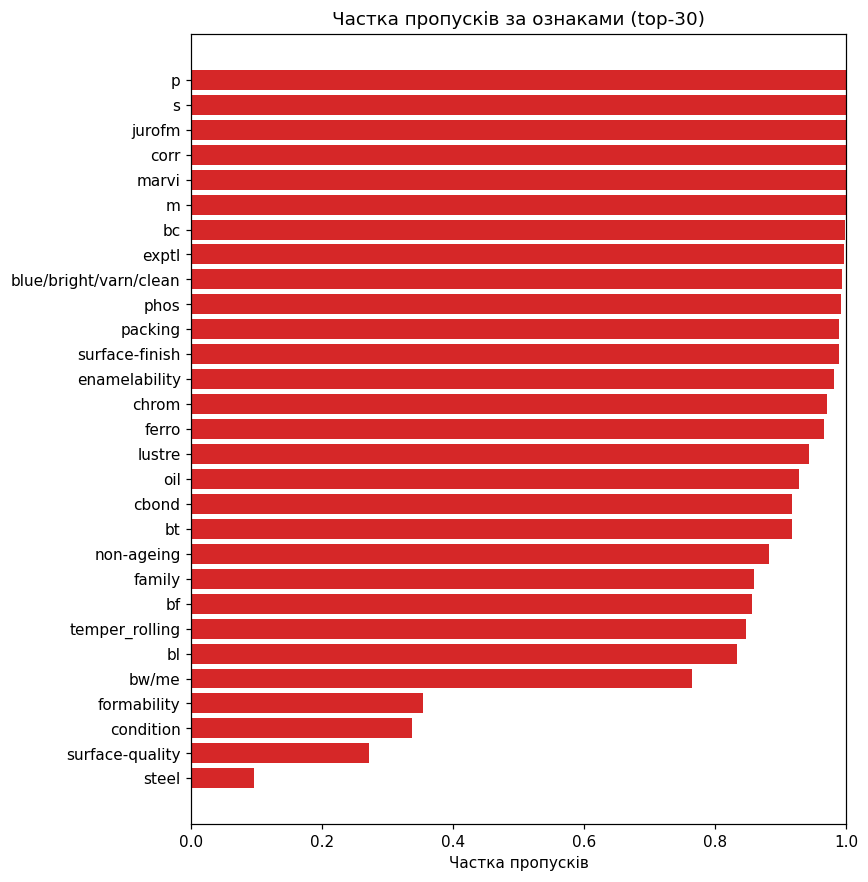

In [4]:
# ---------- 1.3 Частка пропусків: таблиця + графік ----------
miss_df = pd.DataFrame({
    "n_missing": X_raw.isna().sum(),
    "frac_missing": X_raw.isna().mean(),
    "dtype": X_raw.dtypes.astype(str),
}).sort_values("frac_missing", ascending=False)

display(miss_df[miss_df["n_missing"] > 0].style.format({"frac_missing": "{:.3f}"}))

plot_df = miss_df[miss_df["n_missing"] > 0].head(30)
fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(plot_df))))
ax.barh(plot_df.index[::-1], plot_df["frac_missing"][::-1], color="tab:red")
ax.set_xlabel("Частка пропусків")
ax.set_title("Частка пропусків за ознаками (top-30)")
ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

Пропуски дуже поширені: 6 ознак (`p`, `s`, `jurofm`, `corr`, `marvi`, `m`) порожні на 100%, ще багато ознак мають понад 90% пропусків (`bc`, `exptl`, `blue/bright/varn/clean`, `phos`, `packing`, `surface-finish`, `enamelability`, `oil` тощо). Помірну частку мають `formability` (35,4%), `condition` (33,7%), `surface-quality` (27,2%) і `steel` (9,6%). За документацією датасету значна частина цих пропусків **структурна**: ознака просто не визначена для даного виду сталі, тому заповнення медіаною чи модою не має фізичного змісту. Через це пропуск може сам нести інформацію про клас.

In [5]:
# ---------- 1.4 Видалення порожніх і константних ознак ----------
# Фільтр не використовує y, тому не створює витоку цільової змінної.
nun = X_raw.nunique(dropna=True)
empty_cols = nun.index[X_raw.isna().all()].tolist()
const_cols = nun.index[(nun <= 1) & ~X_raw.isna().all()].tolist()
print(f"Порожніх ознак: {len(empty_cols)}")
print(f"Константних (без порожніх): {len(const_cols)}")

X = X_raw.drop(columns=empty_cols + const_cols).copy()
print("Розмір X після видалення:", X.shape)

Порожніх ознак: 6
Константних (без порожніх): 14
Розмір X після видалення: (898, 18)


,n,share
class,,
1,8,0.009
2,99,0.110
3,684,0.762
5,67,0.075
U,40,0.045


Мінімальна кількість об'єктів у класі: 8 (клас '1')


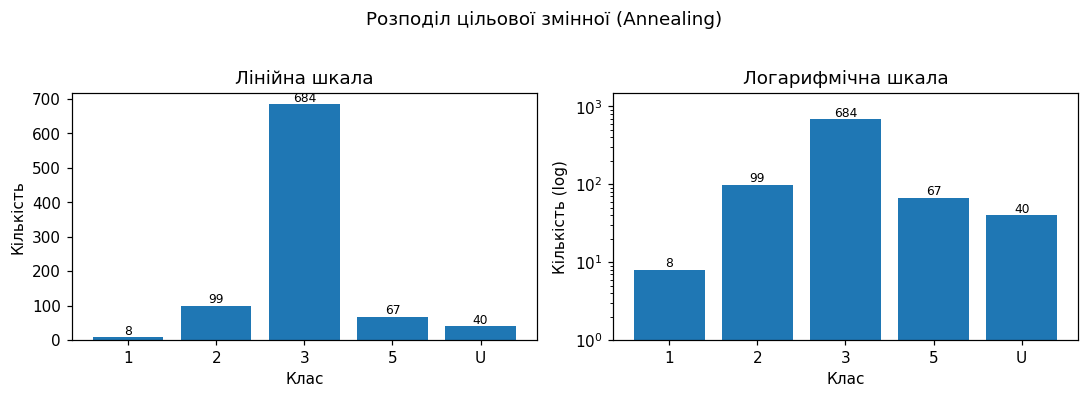

In [6]:
# ---------- 1.5 Розподіл цільової змінної ----------
y_str = y_raw.reset_index(drop=True)
X = X.reset_index(drop=True)

y_counts = y_str.value_counts().sort_index()
y_tab = pd.DataFrame({"n": y_counts, "share": y_counts / len(y_str)})
display(y_tab.style.format({"share": "{:.3f}"}))
print("Мінімальна кількість об'єктів у класі:", y_counts.min(),
      f"(клас '{y_counts.idxmin()}')")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, log in zip(axes, (False, True)):
    ax.bar(y_counts.index, y_counts.values, color="tab:blue")
    for i, v in enumerate(y_counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
    if log:
        ax.set_yscale("log")
        ax.set_ylim(1, y_counts.max() * 2.2)
    ax.set_xlabel("Клас")
    ax.set_ylabel("Кількість" + (" (log)" if log else ""))
    ax.set_title("Логарифмічна шкала" if log else "Лінійна шкала")
fig.suptitle("Розподіл цільової змінної (Annealing)", y=1.02)
plt.tight_layout(); plt.show()

Після видалення 6 порожніх і 14 константних ознак лишилося 18 ознак. Цільова змінна має сильний дисбаланс: клас `3` становить 76,2% (684 об'єкти), `2` має 11,0%, `5` має 7,5%, `U` має 4,5%, а клас `1` лише 0,9% (8 об'єктів). Клас `4` у даних відсутній. Тривіальний класифікатор «завжди 3» мав би accuracy ≈ 0,76, тому accuracy тут слабко інформативна, і основною метрикою обрано macro F1. Клас `1` залишено, бо в train лишається 6 його об'єктів, що дозволяє 5-блочну стратифіковану CV. Але в кожному валідаційному фолді з цього класу припадає лише 1-2 об'єкти, що робить macro F1 нестабільною.

In [7]:
# ---------- 1.6 Пропуск × клас: таблиця спряженості + χ² / Фішер ----------
# Автовибір за очікуваними частотами (правило Кокрена):
#   всі E>=1 і частка E<5 не більша за 20%  -> χ² Пірсона;
#   інакше таблиця 2x2 -> точний тест Фішера;
#   інакше (2xK, K>2) -> χ² з Монте-Карло перестановками.
def mc_chi2_pvalue(mask, y_codes, n_classes, n_perm=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    m = mask.astype(int)

    def chi2_stat(yv):
        t = np.bincount(m * n_classes + yv, minlength=2 * n_classes)
        t = t.reshape(2, n_classes).astype(float)
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        e[e == 0] = np.nan
        return np.nansum((t - e) ** 2 / e)

    obs = chi2_stat(y_codes)
    cnt = sum(chi2_stat(rng.permutation(y_codes)) >= obs - 1e-12 for _ in range(n_perm))
    return (cnt + 1) / (n_perm + 1)

y_codes, _ = pd.factorize(y_str, sort=True)
n_cls_tmp = len(np.unique(y_codes))

top_miss = (X.isna().mean()[lambda s: s > 0]
            .sort_values(ascending=False).head(5).index.tolist())
print("Ознаки з найбільшою часткою пропусків:", top_miss)

summary = []
for col in top_miss:
    mask = X[col].isna().values
    tab = pd.crosstab(pd.Series(np.where(mask, "пропуск", "є значення"), name=col),
                      y_str.rename("клас"))
    print(f"\n=== {col}: частка пропусків = {mask.mean():.3f} ===")
    display(tab)

    chi2, p_chi, dof, exp = stats.chi2_contingency(tab.values, correction=False)
    share_lt5 = (exp < 5).mean()
    if exp.min() >= 1 and share_lt5 <= 0.20:
        test, stat, pval = "χ² Пірсона", chi2, p_chi
    elif tab.shape == (2, 2):
        stat, pval = stats.fisher_exact(tab.values)
        test = "Фішер (точний)"
    else:
        stat = chi2
        pval = mc_chi2_pvalue(mask, y_codes, n_cls_tmp)
        test = "χ² Монте-Карло (5000 перест.)"
    summary.append({"ознака": col, "частка пропусків": mask.mean(),
                    "min E": exp.min(), "частка E<5": share_lt5,
                    "критерій": test, "статистика": stat, "p-value": pval})

summary_df = pd.DataFrame(summary)
display(summary_df.style.format({"частка пропусків": "{:.3f}", "min E": "{:.2f}",
                                 "частка E<5": "{:.2f}", "статистика": "{:.3f}",
                                 "p-value": "{:.4g}"}))

Ознаки з найбільшою часткою пропусків: ['blue/bright/varn/clean', 'packing', 'enamelability', 'oil', 'family']

=== blue/bright/varn/clean: частка пропусків = 0.993 ===


клас,1,2,3,5,U
blue/bright/varn/clean,,,,,
пропуск,7,95,683,67,40
є значення,1,4,1,0,0



=== packing: частка пропусків = 0.990 ===


клас,1,2,3,5,U
packing,,,,,
пропуск,8,99,675,67,40
є значення,0,0,9,0,0



=== enamelability: частка пропусків = 0.982 ===


клас,1,2,3,5,U
enamelability,,,,,
пропуск,8,89,678,67,40
є значення,0,10,6,0,0



=== oil: частка пропусків = 0.929 ===


клас,1,2,3,5,U
oil,,,,,
пропуск,8,99,628,67,32
є значення,0,0,56,0,8



=== family: частка пропусків = 0.860 ===


клас,1,2,3,5,U
family,,,,,
пропуск,6,99,638,0,29
є значення,2,0,46,67,11


,ознака,частка пропусків,min E,частка E<5,критерій,статистика,p-value
0,blue/bright/varn/clean,0.993,0.05,0.50,χ² Монте-Карло (5000 перест.),37.365,0.0009998
1,packing,0.990,0.08,0.40,χ² Монте-Карло (5000 перест.),2.844,0.4493
2,enamelability,0.982,0.14,0.40,χ² Монте-Карло (5000 перест.),44.438,0.0003999
3,oil,0.929,0.57,0.30,χ² Монте-Карло (5000 перест.),24.529,0.0012
4,family,0.860,1.12,0.10,χ² Пірсона,463.748,4.63e-99


Для 5 ознак з найбільшою часткою пропусків перевірено незалежність «пропуск × клас». Для `family` використано χ² Пірсона (χ² = 463,7, p ≈ 5·10⁻⁹⁹), для решти через малі очікувані частоти застосовано χ² з Монте-Карло перестановками: `blue/bright/varn/clean` (p = 0,001), `enamelability` (p = 0,0004), `oil` (p = 0,0012), `packing` (p = 0,449). Для 4 з 5 ознак незалежність відхилено, і ці p-значення лишаються значущими навіть із поправкою Бонферроні (α/5 = 0,01). Лише для `packing` зв'язку не виявлено, але там усього 9 непропущених значень, тож потужність тесту низька. Найяскравіший приклад: `family` пропущена у 99 із 99 об'єктів класу `2`, але в жодному об'єкті класу `5` (0 із 67). Отже, пропуски **не схожі на MCAR**: вони пов'язані з класом (MAR або MNAR). Різницю MAR/MNAR за самими даними розрізнити неможливо, бо для цього потрібні значення, яких ми не спостерігаємо.

In [8]:
# ---------- 1.7 LabelEncoder для цільової змінної ----------
le = LabelEncoder()
y = le.fit_transform(y_str)
class_names = le.classes_.astype(str)
n_classes = len(class_names)
print("Відповідність код -> клас:", dict(enumerate(class_names)))
print("X:", X.shape, "| y:", y.shape, "| класів:", n_classes)

Відповідність код -> клас: {0: '1', 1: '2', 2: '3', 3: '5', 4: 'U'}
X: (898, 18) | y: (898,) | класів: 5


# Блок 2. Split, препроцесор, моделі, pipeline

In [9]:
# ---------- 2.1 Стратифікований split 80/20 ----------
# Тест не використовується до фінальної оцінки (блоки 6-8).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f"train: {X_train.shape}, test: {X_test.shape}")
split_tab = pd.DataFrame({
    "клас": class_names,
    "train": np.bincount(y_train, minlength=n_classes),
    "test": np.bincount(y_test, minlength=n_classes),
}).set_index("клас")
display(split_tab)

train: (718, 18), test: (180, 18)


,train,test
клас,,
1,6,2
2,79,20
3,547,137
5,54,13
U,32,8


In [10]:
# ---------- 2.2 build_preprocessor / make_model / build_pipeline ----------
# Типи колонок беруться зі схеми X_train (не зі значень, тож витоку немає).
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
all_cols = X_train.columns.tolist()
print(f"Числових: {len(num_cols)}, категоріальних: {len(cat_cols)}")

MODEL_NAMES = ["DecisionTree", "RandomForest", "XGBoost"]

def build_preprocessor(with_indicators: bool):
    """A: медіана / мода + OneHot.  B: A + MissingIndicator(features='missing-only')."""
    transformers = [
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),
    ]
    if with_indicators:
        transformers.append(
            ("missingindicator", MissingIndicator(features="missing-only"), all_cols))
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=0.0)

def make_model(name: str, seed: int = SEED, **params):
    if name == "DecisionTree":
        return DecisionTreeClassifier(random_state=seed, **params)
    if name == "RandomForest":
        return RandomForestClassifier(random_state=seed, n_jobs=-1, **params)
    if name == "XGBoost":
        return XGBClassifier(random_state=seed, n_jobs=-1, tree_method="hist",
                             eval_metric="mlogloss", **params)
    raise ValueError(f"Невідома модель: {name}")

def build_pipeline(name: str, with_indicators: bool, **params):
    return Pipeline([
        ("prep", build_preprocessor(with_indicators)),
        ("clf", make_model(name, **params)),
    ])

Числових: 6, категоріальних: 12


In [11]:
# ---------- 2.3 Швидка перевірка pipeline (fit лише на train) ----------
for label, wi in [("A (без індикаторів)", False), ("B (з індикаторами)", True)]:
    prep = build_preprocessor(wi).fit(X_train)
    Xt = prep.transform(X_train)
    names = prep.get_feature_names_out()
    n_ind = sum(n.startswith("missingindicator") for n in names)
    print(f"Варіант {label}: матриця {Xt.shape}, ознак-індикаторів: {n_ind}, "
          f"NaN після препроцесингу: {int(np.isnan(Xt.astype(float)).sum())}")

pipe_demo = build_pipeline("XGBoost", with_indicators=True).fit(X_train, y_train)
print("Smoke test OK:", type(pipe_demo.named_steps["clf"]).__name__)

Варіант A (без індикаторів): матриця (718, 41), ознак-індикаторів: 0, NaN після препроцесингу: 0
Варіант B (з індикаторами): матриця (718, 51), ознак-індикаторів: 10, NaN після препроцесингу: 0
Smoke test OK: XGBClassifier


Pipeline коректно працює на train. Варіант B після препроцесингу має 51 ознаку, з яких частина є бінарними індикаторами пропусків (`missingindicator__...`), а NaN після імпутації не лишається. `Smoke test` для XGBoost пройдено. Типи колонок взято зі схеми `X_train`, а параметри імпутації вивчаються лише на тренувальних даних, тому витоку немає. Нативну підтримку NaN у моделях навмисно не використано, щоб усі три моделі отримували однакові вхідні дані й порівняння було контрольованим.

In [12]:
# ---------- 2.4 Єдині CV-об'єкти + перевірка рідкісних класів у фолдах ----------
# Єдиний RepeatedStratifiedKFold(5,3) для ВСІХ моделей і варіантів A/B
# (однакові розбиття -> коректний парний t-тест у блоці 5).
N_SPLITS, N_REPEATS = 5, 3
cv_rep   = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def min_counts(splits):
    tr_min = np.full(n_classes, np.inf); va_min = np.full(n_classes, np.inf)
    for tr_y, va_y in splits:
        tr_min = np.minimum(tr_min, np.bincount(tr_y, minlength=n_classes))
        va_min = np.minimum(va_min, np.bincount(va_y, minlength=n_classes))
    return tr_min.astype(int), va_min.astype(int)

def cv_splits_y(cv, y_arr):
    Xd = np.zeros((len(y_arr), 1))
    return [(y_arr[a], y_arr[b]) for a, b in cv.split(Xd, y_arr)]

inner_splits = []
for tr_idx, _ in outer_cv.split(np.zeros((len(y_train), 1)), y_train):
    inner_splits += cv_splits_y(inner_cv, y_train[tr_idx])

checks = {
    "RepeatedStratifiedKFold(5,3)": cv_splits_y(cv_rep, y_train),
    "Nested: outer StratifiedKFold(5)": cv_splits_y(outer_cv, y_train),
    "Nested: inner StratifiedKFold(3)": inner_splits,
}
rows = []
for nm, sp in checks.items():
    tr_m, va_m = min_counts(sp)
    for k, cname in enumerate(class_names):
        rows.append({"схема": nm, "клас": cname,
                     "min у train-частині фолда": tr_m[k],
                     "min у valid-частині фолда": va_m[k]})
chk_df = pd.DataFrame(rows)
display(chk_df.pivot(index="клас", columns="схема",
                     values=["min у train-частині фолда", "min у valid-частині фолда"]))

worst_val = chk_df["min у valid-частині фолда"].min()
worst_tr = chk_df["min у train-частині фолда"].min()
print(f"Мінімум об'єктів класу у valid-частині: {worst_val}; у train-частині: {worst_tr}")
assert worst_tr >= 1, "У train-частині фолда зник клас: XGBoost впаде (неперервні мітки)"
if worst_val < 2:
    print("УВАГА: у деяких фолдах рідкісний клас має <2 об'єктів у valid; "
          "macro F1 на таких фолдах нестабільний (використовується zero_division=0).")

min у train-частині фолда                                                                      min у valid-частині фолда                                                              
схема Nested: inner StratifiedKFold(3) Nested: outer StratifiedKFold(5) RepeatedStratifiedKFold(5,3) Nested: inner StratifiedKFold(3) Nested: outer StratifiedKFold(5) RepeatedStratifiedKFold(5,3)
клас                                                                                                                                                                                               
1                                    2                                4                            4                                1                                1                            1
2                                   42                               63                           63                               21                               15                           15
3                                  291                              437                          437                              145                              109                          109
5                                   28                               43                           43                               14                               10                           10
U                                   16                               25                           25                                8                                6                            6

Мінімум об'єктів класу у valid-частині: 1; у train-частині: 2
УВАГА: у деяких фолдах рідкісний клас має <2 об'єктів у valid; macro F1 на таких фолдах нестабільний (використовується zero_division=0).


Перевірка рідкісних класів у фолдах: клас `1` має в train-частині фолдів мінімум 4 об'єкти для зовнішніх схем (RepeatedStratifiedKFold(5,3) і outer 5-fold) і мінімум 2 для внутрішнього 3-fold. Тому XGBoost не вийде з ладу через відсутність класу в навчанні, і твердження `assert` виконано. Проте у валідаційній частині цей клас має лише 1 об'єкт, тож помилка на ньому знижує macro F1 фолда щонайменше на 0,2 (клас має 1 з 5 однакових ваг). Це пояснює великий розкид пофолдових оцінок далі.

# Блок 3. Базова CV (таблиці 1-2)

In [13]:
# ---------- 3.1 Метрики, базові гіперпараметри, допоміжні функції ----------
SCORING = {
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}
METRIC_LABELS = {"f1_macro": "macro F1", "accuracy": "accuracy",
                 "balanced_accuracy": "balanced accuracy"}

BASE_PARAMS = {                      # однакові для A і B (змінюється лише препроцесор)
    "DecisionTree": {},
    "RandomForest": {"n_estimators": 300},
    "XGBoost": {"n_estimators": 200},
}

def fmt_ms(arr, d=4):
    arr = np.asarray(arr, dtype=float)
    return f"{arr.mean():.{d}f} ± {arr.std(ddof=1):.{d}f}"

FOLD_F1 = {}     # (модель, "A"/"B") -> масив довжини 15 (5 фолдів × 3 повтори)
CV_RAW = {}      # усі пофолдові метрики

In [14]:
# ---------- 3.2 Базова RepeatedStratifiedKFold(5,3): 3 моделі × варіанти A/B ----------
VARIANTS = {"A": False, "B": True}

jobs = [(m, v) for m in MODEL_NAMES for v in VARIANTS]
for m, v in tqdm(jobs, desc="Базова CV"):
    pipe = build_pipeline(m, with_indicators=VARIANTS[v], **BASE_PARAMS[m])
    res = cross_validate(pipe, X_train, y_train, cv=cv_rep, scoring=SCORING,
                         n_jobs=1, return_train_score=False)
    CV_RAW[(m, v)] = {k: res[f"test_{k}"] for k in SCORING}
    FOLD_F1[(m, v)] = res["test_f1_macro"].copy()

n_folds_total = N_SPLITS * N_REPEATS
assert all(len(a) == n_folds_total for a in FOLD_F1.values())
print(f"Збережено пофолдові macro F1: {len(FOLD_F1)} комбінацій × {n_folds_total} фолдів")

Базова CV: 100%|██████████| 6/6 [00:26<00:00,  4.49s/it]

Збережено пофолдові macro F1: 6 комбінацій × 15 фолдів


In [15]:
# ---------- 3.3 Таблиця 1 (варіант A) і Таблиця 2 (варіант B) ----------
def cv_table(variant):
    rows = []
    for m in MODEL_NAMES:
        r = {"Модель": m}
        for k, lab in METRIC_LABELS.items():
            r[lab] = fmt_ms(CV_RAW[(m, variant)][k])
        rows.append(r)
    return pd.DataFrame(rows).set_index("Модель")

table1 = cv_table("A")
table2 = cv_table("B")

print("Таблиця 1. Базова CV, варіант A (медіана / мода + OneHot), mean ± std, RepeatedStratifiedKFold(5,3)")
display(table1)
print("Таблиця 2. Базова CV, варіант B (A + MissingIndicator), mean ± std, RepeatedStratifiedKFold(5,3)")
display(table2)

Таблиця 1. Базова CV, варіант A (медіана / мода + OneHot), mean ± std, RepeatedStratifiedKFold(5,3)


,macro F1,accuracy,balanced accuracy
Модель,,,
DecisionTree,0.8806 ± 0.0951,0.9513 ± 0.0178,0.8800 ± 0.0990
RandomForest,0.8960 ± 0.0760,0.9424 ± 0.0125,0.8849 ± 0.0702
XGBoost,0.8778 ± 0.0874,0.9476 ± 0.0143,0.8707 ± 0.0854


Таблиця 2. Базова CV, варіант B (A + MissingIndicator), mean ± std, RepeatedStratifiedKFold(5,3)


,macro F1,accuracy,balanced accuracy
Модель,,,
DecisionTree,0.9450 ± 0.0812,0.9907 ± 0.0097,0.9417 ± 0.0814
RandomForest,0.9308 ± 0.0906,0.9916 ± 0.0054,0.9236 ± 0.0913
XGBoost,0.9246 ± 0.0893,0.9903 ± 0.0069,0.9212 ± 0.0899


Варіант A (без індикаторів): macro F1 0,881 ± 0,095 (DT), 0,896 ± 0,076 (RF), 0,879 ± 0,088 (XGB). Варіант B (з індикаторами): 0,945 ± 0,081 (DT), 0,931 ± 0,091 (RF), 0,924 ± 0,088 (XGB). Індикатори покращили macro F1 в усіх трьох моделей (на 0,035-0,064), а accuracy зросла з 0,94-0,95 до 0,988-0,992. Це узгоджується з аналізом пропусків: пропуск пов'язаний із класом, тому індикатор несе корисний сигнал. Accuracy близька до 1 (ефект стелі), і різниці між моделями в межах одного варіанта (0,01-0,02) значно менші за стандартне відхилення (≈0,08-0,09), тобто можуть бути шумом. Саме тому нижче застосовано статистичний тест.

,DecisionTree|A,DecisionTree|B,RandomForest|A,RandomForest|B,XGBoost|A,XGBoost|B
rep1_fold1,0.9343,0.9603,0.8882,0.9649,0.9007,0.9649
rep1_fold2,0.9347,0.9930,0.9165,0.9837,0.9156,0.9161
rep1_fold3,0.7617,0.9103,0.8666,0.7982,0.7652,0.7982
rep1_fold4,0.9686,1.0000,0.9513,1.0000,0.9791,1.0000
rep1_fold5,0.9491,1.0000,0.9409,0.9930,0.9343,1.0000
rep2_fold1,0.9412,1.0000,0.9459,0.9837,0.9386,0.9837
rep2_fold2,0.8833,1.0000,0.9013,0.9837,0.9343,0.9837
rep2_fold3,0.8981,0.9930,0.9449,0.9324,0.8907,0.9324
rep2_fold4,0.9449,0.9739,0.9356,1.0000,0.9337,0.9809
rep2_fold5,0.7292,0.7921,0.7233,0.7921,0.7314,0.7855


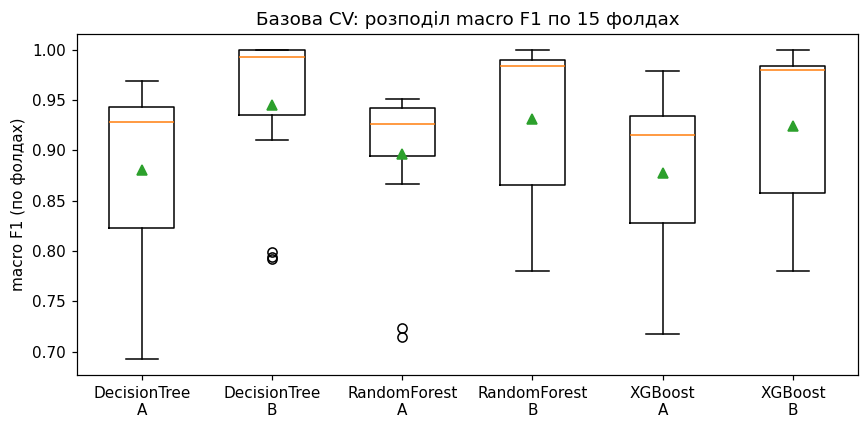

In [16]:
# ---------- 3.4 Пофолдові macro F1 (контроль збережених даних) ----------
fold_df = pd.DataFrame({f"{m}|{v}": FOLD_F1[(m, v)] for (m, v) in FOLD_F1})
fold_df.index = [f"rep{i // N_SPLITS + 1}_fold{i % N_SPLITS + 1}" for i in range(n_folds_total)]
display(fold_df.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
data = [FOLD_F1[(m, v)] for m in MODEL_NAMES for v in VARIANTS]
labels = [f"{m}\n{v}" for m in MODEL_NAMES for v in VARIANTS]
try:
    ax.boxplot(data, tick_labels=labels, showmeans=True)   # Matplotlib >= 3.9
except TypeError:
    ax.boxplot(data, labels=labels, showmeans=True)        # старіші версії
ax.set_ylabel("macro F1 (по фолдах)")
ax.set_title("Базова CV: розподіл macro F1 по 15 фолдах")
plt.tight_layout(); plt.show()

Пофолдові значення показують, звідки береться великий розкид. У варіанті B для RF і XGBoost просідають фолди `rep1_fold3`, `rep2_fold5`, `rep3_fold2`, `rep3_fold5` (macro F1 ≈0,78-0,80). Для **DT-B** таких фолдів лише три: `rep2_fold5`, `rep3_fold2`, `rep3_fold5` — у `rep1_fold3` DT-B тримає 0,91. Це фолди, де єдиний валідаційний об'єкт класу `1` класифіковано неправильно (втрата ≈0,2 macro F1). Отже, стандартне відхилення визначається переважно одним рідкісним класом, а не загальною нестабільністю моделей. Варіант B стабільно вищий за A майже в усіх фолдах (особливо для DT і XGBoost).


# Блок 4. Optuna для варіанта B та nested CV

In [17]:
# ---------- 4.0 Режим швидкої перевірки ----------
import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

# FAST_MODE змінює лише Optuna / nested CV, але не cv_rep з блоку 3
# (щоб пофолдові F1 для t-тесту лишались порівнянними).
N_TRIALS = 5 if FAST_MODE else 30
OUTER_K  = 3 if FAST_MODE else 5
INNER_K  = 2 if FAST_MODE else 3

outer_cv = StratifiedKFold(n_splits=OUTER_K, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=INNER_K, shuffle=True, random_state=SEED)
print(f"FAST_MODE={FAST_MODE}: n_trials={N_TRIALS}, outer={OUTER_K}, inner={INNER_K}, SEED={SEED}")

for tr_idx, _ in outer_cv.split(np.zeros((len(y_train), 1)), y_train):
    for a, _b in inner_cv.split(np.zeros((len(tr_idx), 1)), y_train[tr_idx]):
        assert len(np.unique(y_train[tr_idx][a])) == n_classes, "У inner-train зник клас"
print("Усі класи присутні в кожній inner-train частині.")

FAST_MODE=False: n_trials=30, outer=5, inner=3, SEED=44
Усі класи присутні в кожній inner-train частині.


In [18]:
# ---------- 4.1 suggest_params та tune ----------
def suggest_params(trial, name):
    if name == "DecisionTree":
        return {
            "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
            "max_depth": trial.suggest_int("max_depth", 2, 20),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        }
    if name == "RandomForest":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_int("max_depth", 3, 30),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced_subsample"]),
        }
    if name == "XGBoost":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 8),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 5),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        }
    raise ValueError(name)

def tune(name, X_tr, y_tr, n_trials=None, cv=None, show_progress=False):
    """Optuna отримує ВЕСЬ Pipeline (препроцесор + модель), варіант B.
    Ціль: macro F1 на внутрішній StratifiedKFold."""
    n_trials = N_TRIALS if n_trials is None else n_trials
    cv = inner_cv if cv is None else cv

    def objective(trial):
        params = suggest_params(trial, name)
        pipe = build_pipeline(name, with_indicators=True, **params)
        scores = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring=SCORING["f1_macro"], n_jobs=1)
        return scores.mean()

    study = optuna.create_study(direction="maximize",
                                sampler=TPESampler(seed=SEED),
                                study_name=f"{name}_B")
    study.optimize(objective, n_trials=n_trials, show_progress_bar=show_progress)
    return study

In [19]:
# ---------- 4.2 Tuning на всьому train: study.best_value, best_params ----------
STUDIES = {}
for m in MODEL_NAMES:
    t0 = time.time()
    print(f"\n>>> Optuna: {m} (n_trials={N_TRIALS}, inner CV={INNER_K})")
    STUDIES[m] = tune(m, X_train, y_train, show_progress=True)
    print(f"    best_value (inner CV macro F1) = {STUDIES[m].best_value:.4f} | {time.time() - t0:.0f} c")
    print(f"    best_params = {STUDIES[m].best_params}")


>>> Optuna: DecisionTree (n_trials=30, inner CV=3)


Best trial: 15. Best value: 0.972798: 100%|██████████| 30/30 [00:01<00:00, 18.94it/s]


    best_value (inner CV macro F1) = 0.9728 | 2 c
    best_params = {'criterion': 'entropy', 'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 1}

>>> Optuna: RandomForest (n_trials=30, inner CV=3)


Best trial: 4. Best value: 0.960958: 100%|██████████| 30/30 [01:24<00:00,  2.83s/it]


    best_value (inner CV macro F1) = 0.9610 | 85 c
    best_params = {'n_estimators': 350, 'max_depth': 13, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}

>>> Optuna: XGBoost (n_trials=30, inner CV=3)


Best trial: 12. Best value: 0.919369: 100%|██████████| 30/30 [00:31<00:00,  1.05s/it]

    best_value (inner CV macro F1) = 0.9194 | 32 c
    best_params = {'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.14208562823076623, 'subsample': 0.9799868783597804, 'colsample_bytree': 0.6758978983338385, 'min_child_weight': 1, 'reg_lambda': 2.0722389135263932}


In [20]:
# ---------- 4.3 Nested CV: зовнішня StratifiedKFold, tuning тільки на outer-train ----------
NESTED = {m: {k: [] for k in SCORING} for m in MODEL_NAMES}
NESTED_PARAMS = {m: [] for m in MODEL_NAMES}

for m in MODEL_NAMES:
    splits = list(outer_cv.split(X_train, y_train))
    for i, (tr, va) in enumerate(tqdm(splits, desc=f"Nested CV: {m}")):
        X_tr, y_tr = X_train.iloc[tr], y_train[tr]
        X_va, y_va = X_train.iloc[va], y_train[va]
        st = tune(m, X_tr, y_tr)                      # tuning без доступу до outer-valid
        pipe = build_pipeline(m, with_indicators=True, **st.best_params).fit(X_tr, y_tr)
        pred = pipe.predict(X_va)
        NESTED[m]["f1_macro"].append(f1_score(y_va, pred, average="macro", zero_division=0))
        NESTED[m]["accuracy"].append(accuracy_score(y_va, pred))
        NESTED[m]["balanced_accuracy"].append(balanced_accuracy_score(y_va, pred))
        NESTED_PARAMS[m].append(st.best_params)

NESTED = {m: {k: np.array(v) for k, v in d.items()} for m, d in NESTED.items()}
print("Nested CV завершено.")

Nested CV: XGBoost: 100%|██████████| 5/5 [01:48<00:00, 21.79s/it]

Nested CV завершено.


In [21]:
# ---------- 4.4 Таблиця 3: nested CV + study.best_value ----------
rows = []
for m in MODEL_NAMES:
    rows.append({
        "Модель": m,
        "Nested macro F1": fmt_ms(NESTED[m]["f1_macro"]),
        "Nested accuracy": fmt_ms(NESTED[m]["accuracy"]),
        "Nested balanced acc.": fmt_ms(NESTED[m]["balanced_accuracy"]),
        "study.best_value (inner CV)": f"{STUDIES[m].best_value:.4f}",
        "Базова CV, варіант B, macro F1": fmt_ms(CV_RAW[(m, "B")]["f1_macro"]),
    })
table3 = pd.DataFrame(rows).set_index("Модель")
print(f"Таблиця 3. Nested CV (outer StratifiedKFold({OUTER_K}), inner StratifiedKFold({INNER_K}), "
      f"n_trials={N_TRIALS}), варіант B")
display(table3)

Таблиця 3. Nested CV (outer StratifiedKFold(5), inner StratifiedKFold(3), n_trials=30), варіант B


,Nested macro F1,Nested accuracy,Nested balanced acc.,study.best_value (inner CV),"Базова CV, варіант B, macro F1"
Модель,,,,,
DecisionTree,0.9742 ± 0.0381,0.9889 ± 0.0126,0.9632 ± 0.0556,0.9728,0.9450 ± 0.0812
RandomForest,0.9419 ± 0.0811,0.9889 ± 0.0038,0.9418 ± 0.0825,0.9610,0.9308 ± 0.0906
XGBoost,0.9465 ± 0.0845,0.9903 ± 0.0079,0.9421 ± 0.0830,0.9194,0.9246 ± 0.0893


Nested CV (чесна оцінка): macro F1 0,974 ± 0,038 (DT), 0,942 ± 0,081 (RF), 0,946 ± 0,084 (XGB). Порівняння зі `study.best_value`: у DT вони майже збігаються (0,973 проти 0,974), у **RF** `best_value` = 0,961 вище за nested на 0,019, що відповідає оптимістичному зміщенню (максимум із 30 зашумлених оцінок). У **XGBoost** навпаки: `best_value` = 0,919 нижче за nested (0,946) на 0,027. Це не суперечить теорії, бо внутрішня 3-fold CV навчається на меншій вибірці, а оцінка при великому шумі від класу `1` змінюється в обидва боки. Висновок: `best_value` не можна подавати як оцінку якості моделі, а розбіжності до ±0,03 лежать у межах шуму. Різниця nested vs базова CV (варіант B) становить +0,029 (DT), +0,011 (RF), +0,022 (XGB), але це **не доказ реального приросту від Optuna**: схеми CV різні (5 зовнішніх фолдів vs 15 пофолдових оцінок), у DT найкращі параметри майже дефолтні (`min_samples_split=2`, `min_samples_leaf=1`), а коливання macro F1 в основному від класу `1`.


In [22]:
# ---------- 4.5 Таблиця 4: фінальні моделі на всьому train ----------
FINAL_MODELS, rows = {}, []
for m in MODEL_NAMES:
    t0 = time.time()
    pipe = build_pipeline(m, with_indicators=True, **STUDIES[m].best_params).fit(X_train, y_train)
    FINAL_MODELS[m] = pipe
    rows.append({
        "Модель": m,
        "Найкращі гіперпараметри": STUDIES[m].best_params,
        "best_value (inner CV)": round(STUDIES[m].best_value, 4),
        "Час fit, c": round(time.time() - t0, 2),
        "Ознак після препроцесингу": len(pipe.named_steps["prep"].get_feature_names_out()),
    })
table4 = pd.DataFrame(rows).set_index("Модель")
print("Таблиця 4. Фінальні моделі (варіант B), навчені на всьому train")
with pd.option_context("display.max_colwidth", None):
    display(table4)

Таблиця 4. Фінальні моделі (варіант B), навчені на всьому train


,Найкращі гіперпараметри,best_value (inner CV),"Час fit, c",Ознак після препроцесингу
Модель,,,,
DecisionTree,"{'criterion': 'entropy', 'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 1}",0.9728,0.05,51
RandomForest,"{'n_estimators': 350, 'max_depth': 13, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}",0.9610,1.12,51
XGBoost,"{'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.14208562823076623, 'subsample': 0.9799868783597804, 'colsample_bytree': 0.6758978983338385, 'min_child_weight': 1, 'reg_lambda': 2.0722389135263932}",0.9194,0.38,51


Найкращі гіперпараметри: DT: `criterion=entropy`, `max_depth=17`, `min_samples_split=2`, `min_samples_leaf=1` (тобто майже неглибоко обмежене дерево, що дозволяє виділити рідкісний клас); RF: 350 дерев, `max_depth=13`, `max_features=0.5`, `class_weight=balanced_subsample`; XGB: 300 дерев, `max_depth=7`, `learning_rate≈0,142`, `subsample≈0,98`, `colsample_bytree≈0,676`. Усі моделі після препроцесингу працюють з 51 ознакою, а час навчання мінімальний (DT 0,02 с, RF 0,65 с, XGB 0,19 с — як у таблиці 4).


C:\Users\zhaba\AppData\Local\Temp\ipykernel_25252\1257105267.py:29: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  draw_on(fig, ax_h, lambda m=m: optv.plot_optimization_history(STUDIES[m]))
C:\Users\zhaba\AppData\Local\Temp\ipykernel_25252\1257105267.py:40: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  lambda m=m: optv.plot_param_importances(
C:\Users\zhaba\AppData\Local\Temp\ipykernel_25252\1257105267.py:29: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  draw_on(fig, ax_h, lambda m=m: optv.plot_optimization_history(STUDIES[m]))
C:\Users\zhaba\AppData\Local\Temp\ipykernel_25252\125710526

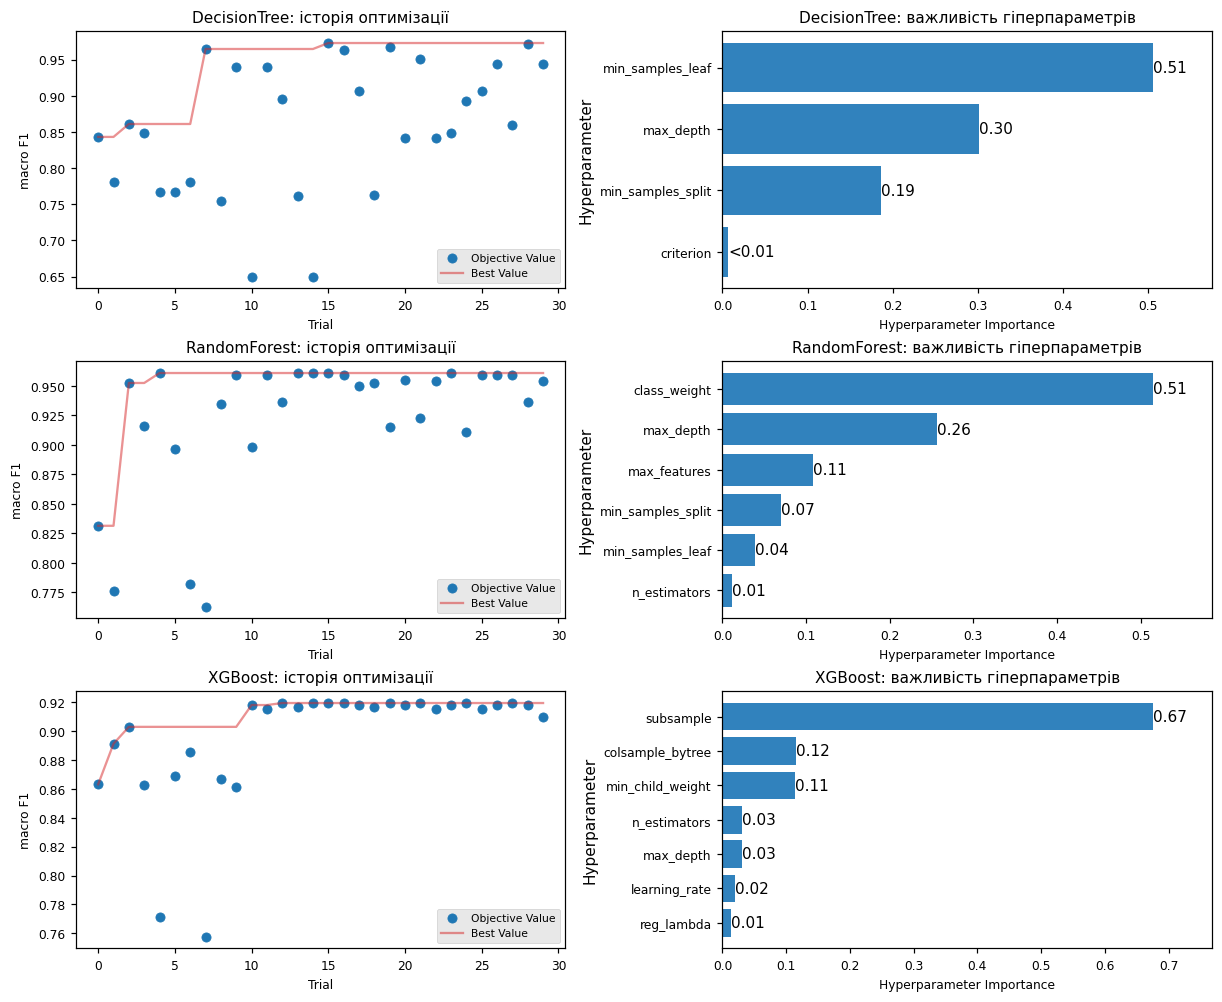

In [23]:
# ---------- 4.6 plot_optimization_history і plot_param_importances ----------
# Одне полотно, 2 графіки в ряд: історія | важливості гіперпараметрів.
import optuna.visualization.matplotlib as optv
from optuna.importance import FanovaImportanceEvaluator

def reset_title(ax, title):
    for loc in ("center", "left", "right"):
        ax.set_title("", loc=loc)
    ax.set_title(title, fontsize=10)

def draw_on(fig, ax, plot_fn):
    """Optuna сама викликає plt.subplots(); підміняємо його, щоб малювати в заданий ax."""
    real_subplots = plt.subplots
    def _into(*args, **kwargs):
        return fig, ax
    plt.subplots = _into
    plt.sca(ax)
    try:
        return plot_fn()
    finally:
        plt.subplots = real_subplots

n = len(MODEL_NAMES)
fig, axes = plt.subplots(n, 2, figsize=(11, 3.0 * n), constrained_layout=True)
axes = np.atleast_2d(axes)

for i, m in enumerate(MODEL_NAMES):
    ax_h = axes[i, 0]
    draw_on(fig, ax_h, lambda m=m: optv.plot_optimization_history(STUDIES[m]))
    reset_title(ax_h, f"{m}: історія оптимізації")
    ax_h.set_ylabel("macro F1", fontsize=8)
    ax_h.set_xlabel("Trial", fontsize=8)
    ax_h.tick_params(labelsize=8)
    ax_h.legend(loc="lower right", fontsize=7, framealpha=0.85)

    ax_i = axes[i, 1]
    try:
        draw_on(
            fig, ax_i,
            lambda m=m: optv.plot_param_importances(
                STUDIES[m], evaluator=FanovaImportanceEvaluator(seed=SEED)))
        reset_title(ax_i, f"{m}: важливість гіперпараметрів")
        ax_i.tick_params(labelsize=8)
        ax_i.set_xlabel(ax_i.get_xlabel(), fontsize=8)
        leg = ax_i.get_legend()
        if leg is not None:
            leg.remove()
    except Exception as e:
        ax_i.clear()
        ax_i.axis("off")
        ax_i.text(
            0.5, 0.5,
            f"{m}: plot_param_importances недоступний\n({type(e).__name__}: {e})",
            ha="center", va="center", fontsize=8)

plt.show()

**DT:** історія дуже мінлива (0,65-0,97), найкраще значення знайдено на 15-й спробі, тобто простір малий, але чутливий до параметрів; найважливіші `min_samples_leaf` (0,52) і `max_depth` (0,29), а `criterion` майже не впливає (<0,01). **RF:** оптимізація збіглася швидко (≈0,96 вже на 4-й спробі), найважливіші `class_weight` (0,51) і `max_depth` (0,26), а `n_estimators` майже не впливає. **XGB:** після ≈10 спроб значення стабілізується на ≈0,92, найважливіший `subsample` (0,68), далі `min_child_weight` (0,12). Оскільки спроб лише 30, оцінки fANOVA-важливості приблизні, тому їх треба трактувати як орієнтир.

# Блок 5. Скоригований t-тест Надо-Бенжіо (таблиця 5)

In [24]:
# ---------- 5.1 Функція тесту ----------
def nadeau_bengio_ttest(d, n_train, n_test):
    """t = mean(d) / sqrt((1/(k*r) + n_test/n_train) * var(d, ddof=1)),  df = k*r - 1."""
    d = np.asarray(d, dtype=float)
    kr = len(d)
    df = kr - 1
    mean_d = d.mean()
    var_d = d.var(ddof=1)
    if var_d <= 1e-16:                      # усі різниці однакові (var = 0)
        if abs(mean_d) <= 1e-16:
            return dict(mean_diff=mean_d, std_diff=0.0, t=0.0, df=df, p=1.0, note="var=0, d=0")
        return dict(mean_diff=mean_d, std_diff=0.0, t=np.sign(mean_d) * np.inf,
                    df=df, p=0.0, note="var=0, d!=0")
    t_stat = mean_d / np.sqrt((1.0 / kr + n_test / n_train) * var_d)
    p = 2.0 * t_dist.sf(abs(t_stat), df)
    return dict(mean_diff=mean_d, std_diff=np.sqrt(var_d), t=t_stat, df=df, p=p, note="")

In [25]:
# ---------- 5.2 Розміри фолдів з ТОГО САМОГО cv_rep ----------
# int random_state -> cv_rep відтворює ті самі розбиття, що й у блоці 3.
splits_rep = list(cv_rep.split(np.zeros((len(y_train), 1)), y_train))
assert len(splits_rep) == N_SPLITS * N_REPEATS
n_train_fold = np.mean([len(a) for a, _ in splits_rep])
n_test_fold  = np.mean([len(b) for _, b in splits_rep])
print(f"k·r = {len(splits_rep)}, n_train(фолд) ≈ {n_train_fold:.1f}, "
      f"n_test(фолд) ≈ {n_test_fold:.1f}, відношення = {n_test_fold / n_train_fold:.4f}")

k·r = 15, n_train(фолд) ≈ 574.4, n_test(фолд) ≈ 143.6, відношення = 0.2500


In [26]:
# ---------- 5.3 Таблиця 5: A vs B для кожної моделі + топ-2 моделі у варіанті B ----------
rows = []
for m in MODEL_NAMES:
    d = FOLD_F1[(m, "B")] - FOLD_F1[(m, "A")]                 # B − A по фолдах
    r = nadeau_bengio_ttest(d, n_train_fold, n_test_fold)
    rows.append({"Порівняння": f"{m}: B vs A (B − A)", **r})

rank_B = sorted(MODEL_NAMES, key=lambda m: FOLD_F1[(m, "B")].mean(), reverse=True)
top1, top2 = rank_B[0], rank_B[1]
d = FOLD_F1[(top1, "B")] - FOLD_F1[(top2, "B")]
r = nadeau_bengio_ttest(d, n_train_fold, n_test_fold)
rows.append({"Порівняння": f"Варіант B: {top1} vs {top2} (топ-2)", **r})

table5 = pd.DataFrame(rows).set_index("Порівняння")
table5["значущо (α=0.05)"] = table5["p"] < 0.05
table5 = table5.rename(columns={"mean_diff": "mean(d)", "std_diff": "std(d)",
                                "t": "t", "df": "df", "p": "p-value", "note": "примітка"})
print("Таблиця 5. Скоригований t-тест Надо-Бенжіо на пофолдових macro F1 "
      f"(RepeatedStratifiedKFold({N_SPLITS},{N_REPEATS}), df = {len(splits_rep) - 1})")
display(table5.style.format({"mean(d)": "{:+.4f}", "std(d)": "{:.4f}",
                             "t": "{:.3f}", "p-value": "{:.4g}"}))
print("Топ-2 у варіанті B за середнім macro F1 (базова CV):", rank_B[:2])

Таблиця 5. Скоригований t-тест Надо-Бенжіо на пофолдових macro F1 (RepeatedStratifiedKFold(5,3), df = 14)


,mean(d),std(d),t,df,p-value,примітка,значущо (α=0.05)
Порівняння,,,,,,,
DecisionTree: B vs A (B − A),+0.0644,0.0372,3.075,14,0.008229,,True
RandomForest: B vs A (B − A),+0.0348,0.0574,1.077,14,0.2998,,False
XGBoost: B vs A (B − A),+0.0468,0.0208,4.008,14,0.001295,,True
Варіант B: DecisionTree vs RandomForest (топ-2),+0.0142,0.0330,0.766,14,0.4566,,False


Топ-2 у варіанті B за середнім macro F1 (базова CV): ['DecisionTree', 'RandomForest']


 Варіант B кращий за A **значуще** для DT (d̄ = +0,064; p = 0,008) і XGBoost (d̄ = +0,0468; p = 0,0013). Для RF різниця (+0,035) **незначуща** (p = 0,30) через великий розкид різниць по фолдах (std = 0,057). Між двома найкращими моделями у варіанті B (DT і RF) різниця 0,014 **незначуща** (t = 0,77; p = 0,457). Тобто за базовою CV ми не можемо стверджувати, що одна модель краща за іншу. Скоригований тест консервативніший за звичайний парний, бо додає до дисперсії доданок n_test/n_train, що враховує залежність оцінок на перекритих тренувальних наборах.

# Блок 6. Фінальна оцінка на тесті

In [27]:
# ---------- 6.1 Єдиний прогноз на тесті (тест використовується тут уперше) ----------
PRED_TEST = {m: FINAL_MODELS[m].predict(X_test) for m in MODEL_NAMES}   # для блоків 7-8

rows = []
for m in MODEL_NAMES:
    p = PRED_TEST[m]
    rows.append({
        "Модель": m,
        "accuracy": accuracy_score(y_test, p),
        "macro F1": f1_score(y_test, p, average="macro", zero_division=0),
        "balanced accuracy": balanced_accuracy_score(y_test, p),
    })
table6 = pd.DataFrame(rows).set_index("Модель")
print(f"Таблиця 6. Фінальна оцінка на тесті (n_test = {len(y_test)})")
display(table6.style.format("{:.4f}"))

BEST_MODEL = table6["macro F1"].idxmax()
print("Найкраща модель за macro F1 на тесті:", BEST_MODEL)

Таблиця 6. Фінальна оцінка на тесті (n_test = 180)


,accuracy,macro F1,balanced accuracy
Модель,,,
DecisionTree,0.9889,0.9408,0.9650
RandomForest,1.0000,1.0000,1.0000
XGBoost,1.0000,1.0000,1.0000


Найкраща модель за macro F1 на тесті: RandomForest


DT: accuracy 0,989, macro F1 0,941, balanced accuracy 0,965. RF і XGB: 1,000 / 1,000 / 1,000. На тесті помиляється лише DT (2 об'єкти із 180); RF і XGB дають однаковий ідеальний результат. Підпис «найкраща модель = RF» з'являється лише тому, що при рівності macro F1 `idxmax` бере першу модель у списку. Тестові значення вищі за CV-оцінки й мають значно меншу дисперсію, бо в тесті лише 2 об'єкти класу `1`, 8 об'єктів класу `U` і 13 класу `5`; кожен із них суттєво впливає на macro F1. Тому ідеальний результат RF і XGB не слід трактувати як перевагу однієї моделі над іншою: це лише одна вибірка з малою кількістю рідкісних об'єктів, а різницю DT і RF за CV визнано статистично незначущою.


In [28]:
# ---------- 6.2 classification_report найкращої моделі ----------
print(f"classification_report: {BEST_MODEL}\n")
print(classification_report(y_test, PRED_TEST[BEST_MODEL],
                            labels=np.arange(n_classes), target_names=class_names,
                            digits=4, zero_division=0))

classification_report: RandomForest

              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000         2
           2     1.0000    1.0000    1.0000        20
           3     1.0000    1.0000    1.0000       137
           5     1.0000    1.0000    1.0000        13
           U     1.0000    1.0000    1.0000         8

    accuracy                         1.0000       180
   macro avg     1.0000    1.0000    1.0000       180
weighted avg     1.0000    1.0000    1.0000       180



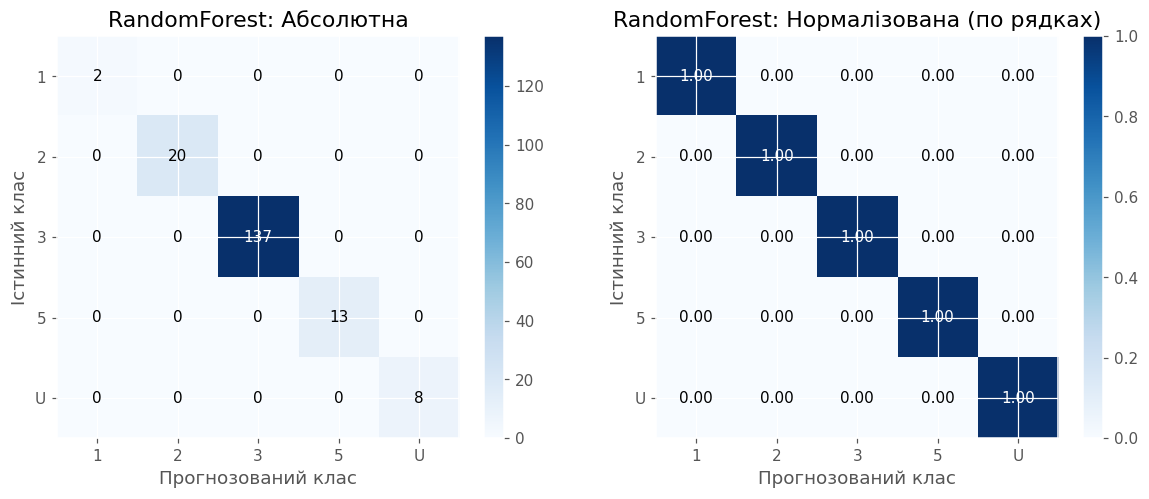

In [29]:
# ---------- 6.3 Матриці плутанини: абсолютна + нормалізована по рядках ----------
cm = confusion_matrix(y_test, PRED_TEST[BEST_MODEL], labels=np.arange(n_classes))
row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, out=np.zeros(cm.shape, dtype=float), where=row_sums > 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, M, title, fmt in [(axes[0], cm, "Абсолютна", "d"),
                          (axes[1], cm_norm, "Нормалізована (по рядках)", ".2f")]:
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=(None if fmt == "d" else 1))
    ax.set_xticks(range(n_classes)); ax.set_xticklabels(class_names)
    ax.set_yticks(range(n_classes)); ax.set_yticklabels(class_names)
    ax.set_xlabel("Прогнозований клас"); ax.set_ylabel("Істинний клас")
    ax.set_title(f"{BEST_MODEL}: {title}")
    thr = M.max() / 2 if M.max() > 0 else 0.5
    for i in range(n_classes):
        for j in range(n_classes):
            ax.text(j, i, format(M[i, j], fmt), ha="center", va="center",
                    color="white" if M[i, j] > thr else "black")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

Матрицю плутанини побудовано для моделі, яку код позначив найкращою (RF). І RF, і XGB на тесті не зробили жодної помилки: уся маса матриці на діагоналі (2, 20, 137, 13, 8 для класів 1, 2, 3, 5, U), а у `classification_report` усі precision, recall і F1 дорівнюють 1,0. Тому нормалізована матриця — одиничні значення на діагоналі, і з неї не видно, які класи плутаються. Про це свідчать помилки DT на тесті (таблиця 7) і out-of-fold розбіжності.


In [30]:
# ---------- 6.4 Пари класів, що найчастіше плутаються ----------
pairs = []
for i in range(n_classes):
    for j in range(n_classes):
        if i != j and cm[i, j] > 0:
            pairs.append({"істинний → прогнозований": f"{class_names[i]} → {class_names[j]}",
                          "кількість": int(cm[i, j]),
                          "частка від істинного класу": cm[i, j] / row_sums[i, 0]})

if pairs:
    pairs_df = (pd.DataFrame(pairs)
                .sort_values(["кількість", "частка від істинного класу"], ascending=False)
                .reset_index(drop=True))
    print(f"Спрямовані помилки ({BEST_MODEL}):")
    display(pairs_df.style.format({"частка від істинного класу": "{:.2%}"}))

    unord = []
    for i in range(n_classes):
        for j in range(i + 1, n_classes):
            tot = int(cm[i, j] + cm[j, i])
            if tot > 0:
                unord.append({"пара": f"{class_names[i]} ↔ {class_names[j]}",
                              f"{class_names[i]}→{class_names[j]}": int(cm[i, j]),
                              f"{class_names[j]}→{class_names[i]}": int(cm[j, i]),
                              "разом": tot})
    print("\nНеупорядковані пари:")
    display(pd.DataFrame(unord).sort_values("разом", ascending=False).reset_index(drop=True))
else:
    print(f"{BEST_MODEL}: на тесті немає жодної помилки класифікації.")

RandomForest: на тесті немає жодної помилки класифікації.


Оскільки для RF помилок немає, таблиці пар порожні («на тесті немає жодної помилки класифікації»). Для аналізу плутанини класів використано розбіжності з таблиці 7: серед out-of-fold об'єктів найчастіше змішуються класи `3` і `2` (напр., id 746, 827, 101 та інші), а також `3` і `U` (id 16, 356, 619). Клас `1` також плутають: id 406 одна модель (DT) визначила правильно, інші дві помилилися. Причини: клас `3` домінує, класи `2`/`3`/`U` мають схожі значення ключових ознак (`hardness`, `carbon`, `strength`), а клас `1` має лише 8 об'єктів.

# Блок 7. Важливість ознак

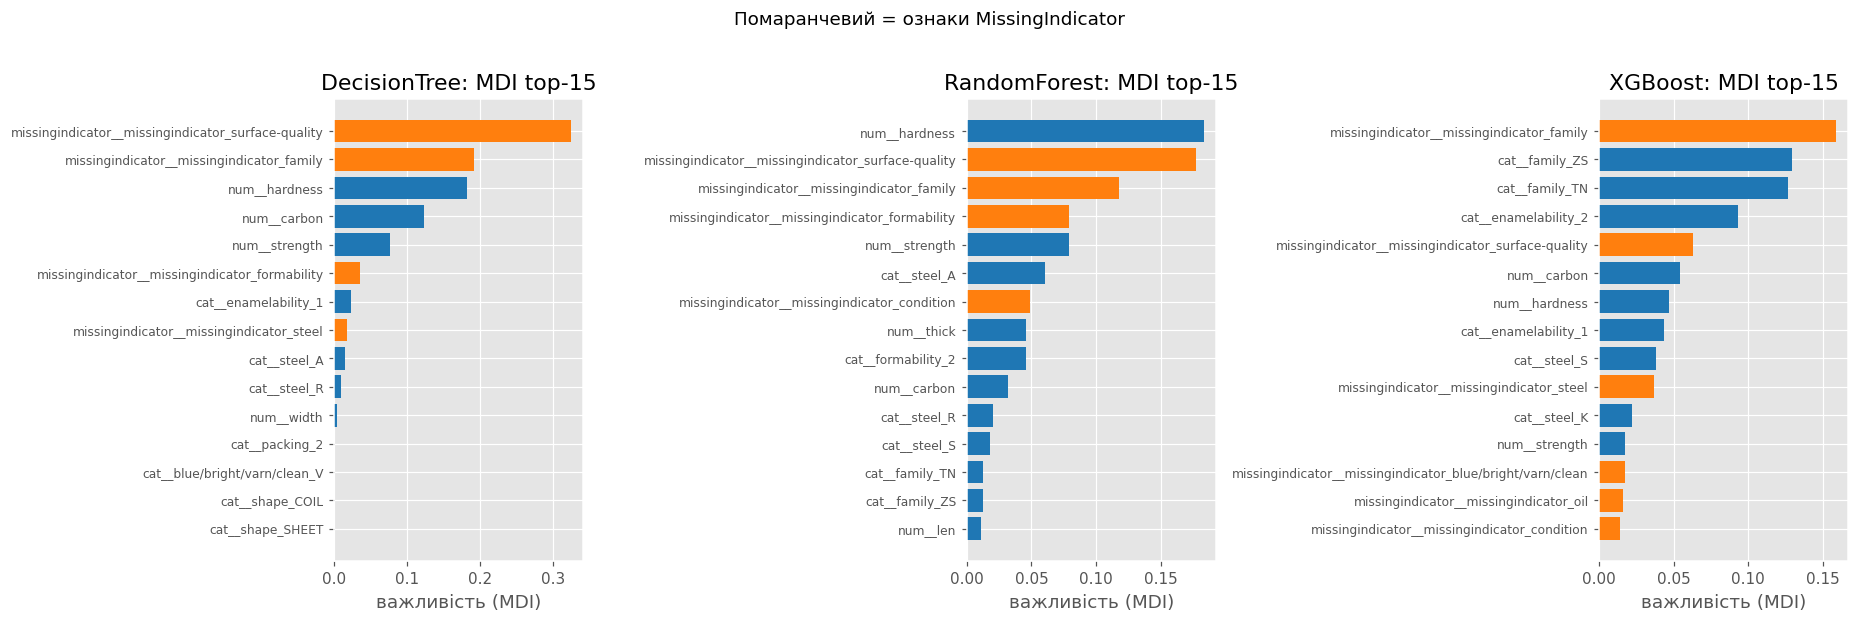

DecisionTree: missingindicator_* у top-15 за MDI: ТАК (4)
RandomForest: missingindicator_* у top-15 за MDI: ТАК (4)
XGBoost: missingindicator_* у top-15 за MDI: ТАК (6)


,missingindicator_* у top-15 (MDI),кількість,ознаки
Модель,,,
DecisionTree,так,4,missingindicator__missingindicator_surface-qua...
RandomForest,так,4,missingindicator__missingindicator_surface-qua...
XGBoost,так,6,"missingindicator__missingindicator_family, mis..."


In [31]:
# ---------- 7.1 MDI (feature_importances_), top-15 ----------
# Для DecisionTree / RandomForest це середнє зниження неоднорідності,
# для XGBoost (sklearn API) за замовчуванням - gain.
MDI = {}
for m in MODEL_NAMES:
    pipe = FINAL_MODELS[m]
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=names)
    MDI[m] = imp.sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, m in zip(axes, MODEL_NAMES):
    top = MDI[m].head(15)[::-1]
    colors = ["tab:orange" if "missingindicator" in n else "tab:blue" for n in top.index]
    ax.barh(top.index, top.values, color=colors)
    ax.set_title(f"{m}: MDI top-15")
    ax.set_xlabel("важливість (MDI)")
    ax.tick_params(axis="y", labelsize=8)
plt.suptitle("Помаранчевий = ознаки MissingIndicator", y=1.02)
plt.tight_layout(); plt.show()

rows = []
for m in MODEL_NAMES:
    top15 = MDI[m].head(15)
    ind = [n for n in top15.index if "missingindicator" in n]
    rows.append({"Модель": m, "missingindicator_* у top-15 (MDI)": "так" if ind else "ні",
                 "кількість": len(ind), "ознаки": ", ".join(ind) if ind else "-"})
    print(f"{m}: missingindicator_* у top-15 за MDI: {'ТАК' if ind else 'НІ'} ({len(ind)})")
display(pd.DataFrame(rows).set_index("Модель"))

Індикатори пропусків потрапили до top-15 у всіх трьох моделей: 4 у DT (`surface-quality`, `family`, `formability`, `steel`), 4 у RF (`surface-quality`, `family`, `formability`, `condition`) і 6 у XGBoost (`family`, `surface-quality`, `steel`, `blue/bright/varn/clean`, `oil`, `condition`). У DT індикатор `surface-quality` взагалі перший (≈0,32), а `family` другий. Це узгоджується з аналізом пропусків: факт пропуску пов'язаний із класом, і моделі його використовують. MDI рахується на оброблених ознаках (після one-hot), тому враховує індикатори окремо від самої ознаки, а також може завищувати важливість ознак із багатьма унікальними значеннями (числові `hardness`, `carbon`) і розпорошувати важливість між корельованими ознаками.

Permutation importance: 100%|██████████| 3/3 [00:21<00:00,  7.29s/it]


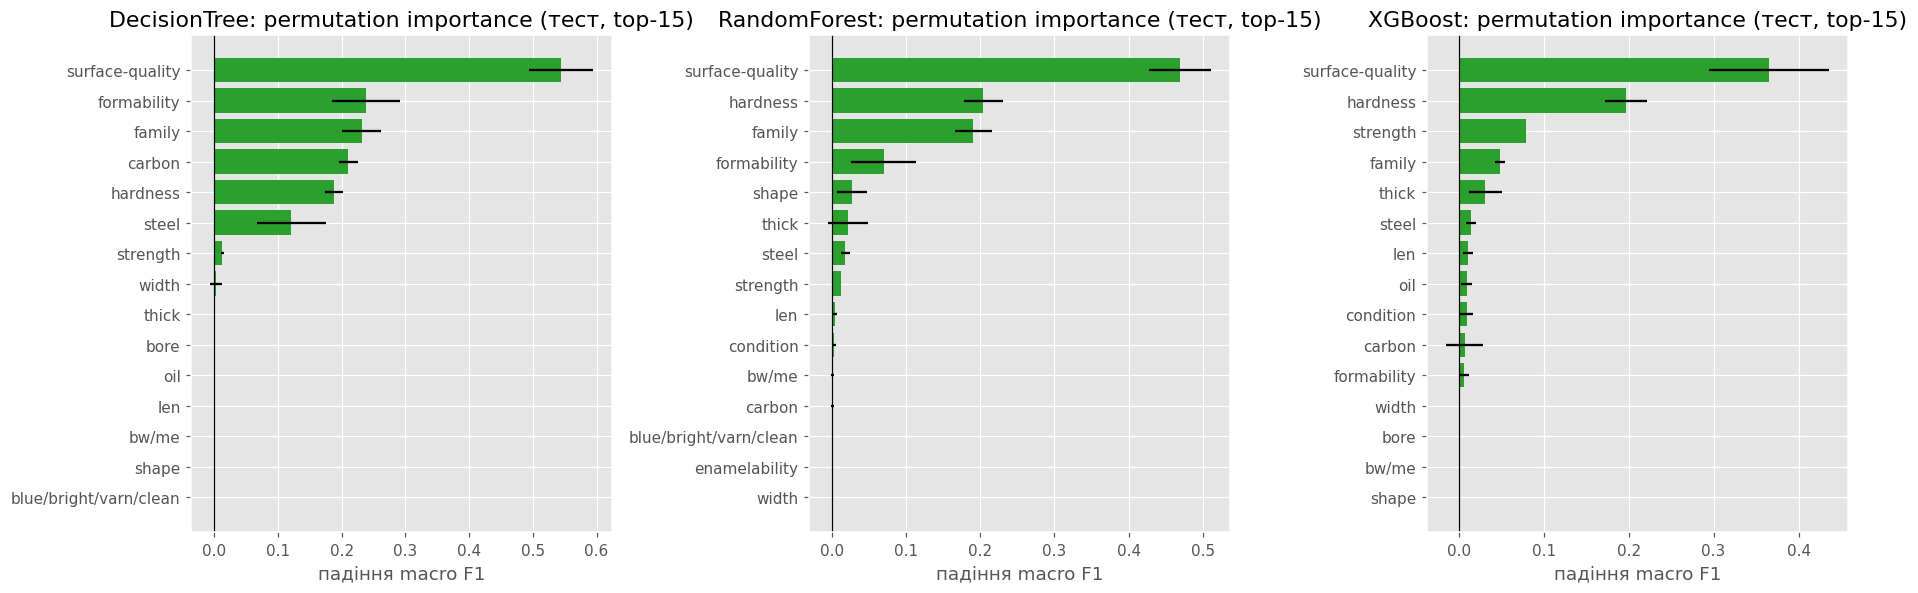

DecisionTree         RandomForest         XGBoost        
                               mean     std         mean     std    mean     std
surface-quality              0.5446  0.0500       0.4691  0.0420  0.3649  0.0707
formability                  0.2379  0.0535       0.0700  0.0440  0.0062  0.0060
family                       0.2314  0.0307       0.1907  0.0249  0.0486  0.0062
carbon                       0.2107  0.0153       0.0006  0.0018  0.0073  0.0220
hardness                     0.1881  0.0142       0.2040  0.0264  0.1969  0.0249
steel                        0.1213  0.0547       0.0180  0.0060  0.0148  0.0063
strength                     0.0128  0.0021       0.0120  0.0000  0.0794  0.0000
width                        0.0034  0.0092       0.0000  0.0000  0.0000  0.0000
thick                        0.0000  0.0000       0.0221  0.0270  0.0316  0.0198
bore                         0.0000  0.0000          NaN     NaN  0.0000  0.0000
oil                          0.0000  0.0000          NaN     NaN  0.0098  0.0064
len                          0.0000  0.0000       0.0035  0.0029  0.0112  0.0056
bw/me                        0.0000  0.0000       0.0006  0.0018  0.0000  0.0000
shape                        0.0000  0.0000       0.0274  0.0202  0.0000  0.0000
blue/bright/varn/clean       0.0000  0.0000       0.0000  0.0000     NaN     NaN
condition                       NaN     NaN       0.0028  0.0028  0.0097  0.0077
enamelability                   NaN     NaN       0.0000  0.0000     NaN     NaN

In [32]:
# ---------- 7.2 Permutation importance на тесті (весь pipeline, f1_macro, n_repeats=10) ----------
# Перестановка відбувається по ВИХІДНИХ колонках X_test (до імпутації),
# тож внесок індикатора пропуску об'єднується з внеском самої ознаки.
PERM = {}
for m in tqdm(MODEL_NAMES, desc="Permutation importance"):
    r = permutation_importance(FINAL_MODELS[m], X_test, y_test, scoring="f1_macro",
                               n_repeats=10, random_state=SEED, n_jobs=1)
    PERM[m] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std},
                           index=X_test.columns).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, m in zip(axes, MODEL_NAMES):
    top = PERM[m].head(15)[::-1]
    ax.barh(top.index, top["mean"], xerr=top["std"], color="tab:green")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{m}: permutation importance (тест, top-15)")
    ax.set_xlabel("падіння macro F1")
plt.tight_layout(); plt.show()

display(pd.concat({m: PERM[m].head(15).round(4) for m in MODEL_NAMES}, axis=1))

Для всіх моделей найважливіша `surface-quality`: падіння macro F1 на 0,54 (DT), 0,47 (RF), 0,37 (XGB). Друга спільна ознака `hardness` (≈0,19-0,20). Далі моделі розходяться: DT використовує `formability` (0,24), `family` (0,23), `carbon` (0,21) і `steel` (0,12); RF `family` (0,19); XGBoost `strength` (0,07). Для `carbon` вага в DT 0,21, але в RF і XGB ≈0, а для `family` у XGB важливість ≈0,049, хоча її індикатор має високий MDI. Узгодженість MDI і permutation лише часткова: перестановка на тесті показує, що ознака не потрібна, якщо її інформацію дублюють інші ознаки (корельовані), тоді як MDI розподіляє внесок між ними. Різниця між моделями пояснюється тим, що одне дерево покладається на жорсткі пороги однієї ознаки, а ансамблі розподіляють залежність між багатьма ознаками. Також permutation на малому тесті має значну дисперсію.

# Блок 8. Розбіжності моделей та SHAP

In [33]:
# ---------- 8.1 Розбіжності на тесті, доповнення out-of-fold, таблиця 7 ----------
P_test = np.column_stack([PRED_TEST[m] for m in MODEL_NAMES])
mask_test = ~(P_test == P_test[:, [0]]).all(axis=1)
print(f"Об'єктів у тесті, де прогнози трьох моделей не всі однакові: {int(mask_test.sum())}")

def make_rows(mask, preds, y_true, X_frame, source):
    out = []
    for pos in np.where(mask)[0]:
        row = {"джерело": source, "id (індекс X)": int(X_frame.index[pos]), "_pos": int(pos),
               "істинний": class_names[y_true[pos]]}
        for k, m in enumerate(MODEL_NAMES):
            row[m] = class_names[preds[pos, k]]
        out.append(row)
    return out

rows7 = make_rows(mask_test, P_test, y_test, X_test, "тест (final-моделі)")

MAX_OOF_ROWS = 10
OOF_USED = False
if mask_test.sum() < 3:
    # out-of-fold: клони pipeline з фінальними гіперпараметрами, ті самі фолди для всіх моделей
    OOF_USED = True
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    OOF = {m: cross_val_predict(clone(FINAL_MODELS[m]), X_train, y_train, cv=oof_cv, n_jobs=1)
           for m in tqdm(MODEL_NAMES, desc="OOF-прогнози")}
    P_oof = np.column_stack([OOF[m] for m in MODEL_NAMES])
    mask_oof = ~(P_oof == P_oof[:, [0]]).all(axis=1)
    print(f"Out-of-fold (train, StratifiedKFold(5)): розбіжностей {int(mask_oof.sum())}, "
          f"у таблицю береться до {MAX_OOF_ROWS}")
    oof_rows = make_rows(mask_oof, P_oof, y_train, X_train, "OOF (train)")
    rows7 += oof_rows[:MAX_OOF_ROWS]

table7 = pd.DataFrame(rows7)
print("\nТаблиця 7. Об'єкти, де прогнози моделей розходяться")
if len(table7):
    display(table7.drop(columns="_pos").reset_index(drop=True))
else:
    print("Розбіжностей немає ні на тесті, ні в OOF.")

Об'єктів у тесті, де прогнози трьох моделей не всі однакові: 2


OOF-прогнози: 100%|██████████| 3/3 [00:07<00:00,  2.33s/it]

Out-of-fold (train, StratifiedKFold(5)): розбіжностей 11, у таблицю береться до 10

Таблиця 7. Об'єкти, де прогнози моделей розходяться


,джерело,id (індекс X),істинний,DecisionTree,RandomForest,XGBoost
0,тест (final-моделі),17,U,3,U,U
1,тест (final-моделі),682,2,1,2,2
2,OOF (train),746,3,2,3,2
3,OOF (train),585,3,3,2,3
4,OOF (train),406,1,1,2,3
5,OOF (train),588,2,3,2,2
6,OOF (train),804,2,3,2,2
7,OOF (train),827,3,2,3,3
8,OOF (train),16,U,U,3,3
9,OOF (train),101,3,2,3,2


На тесті є лише 2 розбіжні об'єкти, і в обох помиляється лише DT: id 17 (істинний клас `U`: DT → `3`, RF і XGB → `U`) та id 682 (істинний `2`: DT → `1`, RF і XGB → `2`). Оскільки їх менше трьох, таблицю доповнено 10 out-of-fold об'єктами з train (прогнози `cross_val_predict` від клонів pipeline, а не прогнози на тренувальних даних). Перші два рядки — із тесту, решта — із OOF; джерело зазначено в першому стовпці. Розбіжності концентруються на межі класів `2`/`3`/`U` та на рідкісному класі `1`.

In [34]:
# ---------- 8.2 Вибір об'єкта; вихідні ознаки до імпутації і чим заповнені ----------
# Пріоритет - об'єкт із тесту; якщо розбіжностей на тесті немає - перший OOF-об'єкт.
CHOSEN_ROW = 0           # номер рядка таблиці 7 (можна змінити вручну)
assert len(table7) > 0, "Немає розбіжностей для аналізу"
sel = table7.iloc[CHOSEN_ROW]
if sel["джерело"].startswith("тест"):
    obj_X, obj_y = X_test.iloc[[int(sel["_pos"])]], y_test[int(sel["_pos"])]
else:
    obj_X, obj_y = X_train.iloc[[int(sel["_pos"])]], y_train[int(sel["_pos"])]
    print("УВАГА: об'єкт із train; final-моделі його вже бачили під час навчання "
          "(розбіжність взято з OOF-прогнозів).")
print(f"Джерело: {sel['джерело']} | id = {sel['id (індекс X)']} | істинний клас: {class_names[obj_y]}")

prep0 = FINAL_MODELS[MODEL_NAMES[0]].named_steps["prep"]     # препроцесор однаковий для всіх моделей
fill = {}
num_stats = prep0.named_transformers_["num"].statistics_
fill.update(dict(zip(num_cols, num_stats)))
cat_stats = prep0.named_transformers_["cat"].named_steps["imp"].statistics_
fill.update(dict(zip(cat_cols, cat_stats)))

rows = []
for c in all_cols:
    v = obj_X.iloc[0][c]
    miss = pd.isna(v)
    rows.append({"ознака": c, "значення (до імпутації)": "<ПРОПУСК>" if miss else v,
                 "пропуск": miss, "чим заповнено": fill[c] if miss else "-"})
obj_table = pd.DataFrame(rows).set_index("ознака")
display(obj_table)
print("Пропущено ознак:", int(obj_table["пропуск"].sum()), "з", len(all_cols))

Джерело: тест (final-моделі) | id = 17 | істинний клас: U


,значення (до імпутації),пропуск,чим заповнено
ознака,,,
family,<ПРОПУСК>,True,TN
steel,A,False,-
carbon,0,False,-
hardness,80,False,-
condition,<ПРОПУСК>,True,S
formability,<ПРОПУСК>,True,2
strength,0,False,-
surface-quality,G,False,-
enamelability,<ПРОПУСК>,True,2


Пропущено ознак: 7 з 18


Для детального аналізу обрано об'єкт id 17 (клас `U`). Із 18 ознак пропущено 7: `family` (заповнено `TN`), `condition` (`S`), `formability` (`2`), `enamelability` (`2`), `bw/me` (`B`), `blue/bright/varn/clean` (`B`) і `packing` (`3`). Тобто 7 ознак заповнено найчастішими значеннями (модою) з тренувальної вибірки, які можуть не відповідати реальності: для структурних пропусків така імпутація не має змісту. Непропущені значення: `surface-quality = G`, `hardness = 80`, `carbon = 0`, `width = 610`, `thick = 0,8`.

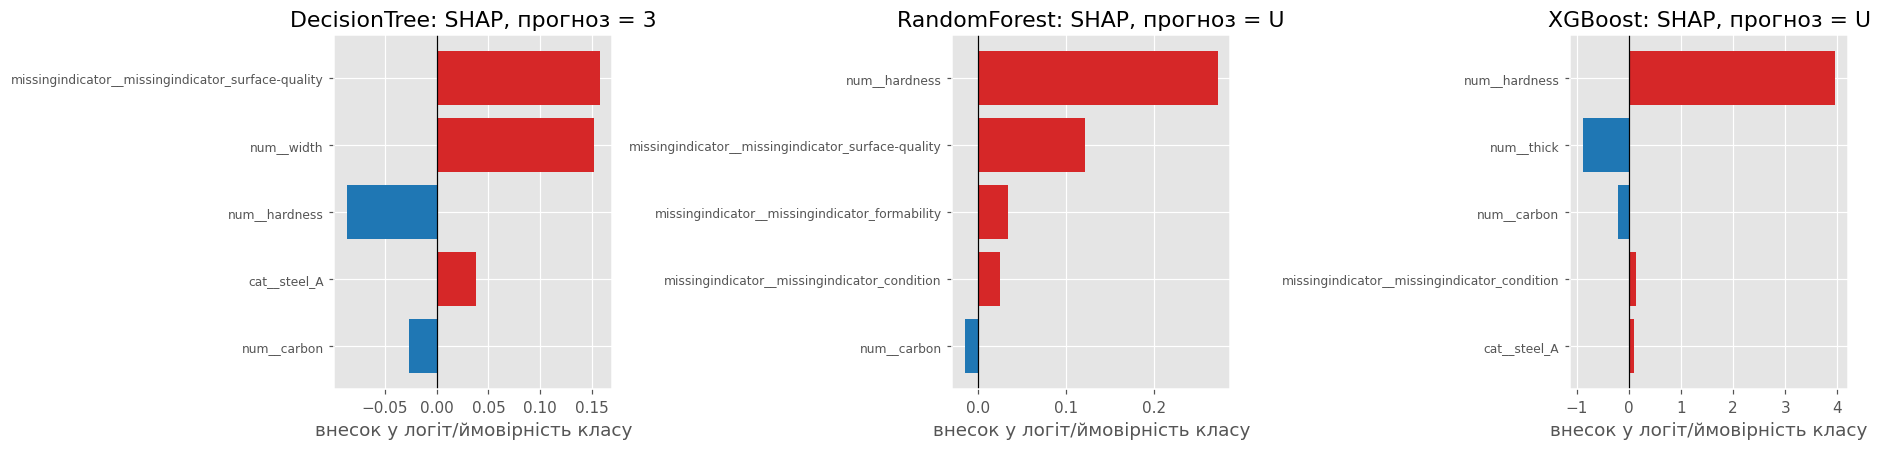


DecisionTree: top-5 ознак за |SHAP| (клас, який прогнозує модель)


,SHAP
missingindicator__missingindicator_surface-quality,0.157249
num__width,0.151297
num__hardness,-0.086316
cat__steel_A,0.038225
num__carbon,-0.027086



RandomForest: top-5 ознак за |SHAP| (клас, який прогнозує модель)


,SHAP
num__hardness,0.271964
missingindicator__missingindicator_surface-quality,0.120745
missingindicator__missingindicator_formability,0.033310
missingindicator__missingindicator_condition,0.024189
num__carbon,-0.015460



XGBoost: top-5 ознак за |SHAP| (клас, який прогнозує модель)


,SHAP
num__hardness,3.962026
num__thick,-0.881685
num__carbon,-0.199345
missingindicator__missingindicator_condition,0.143885
cat__steel_A,0.093583


In [35]:
# ---------- 8.3 SHAP (TreeExplainer) для прогнозованого класу, top-5, bar-графік ----------
import shap

feat_names = prep0.get_feature_names_out()
x_t = np.asarray(prep0.transform(obj_X), dtype=float)
n_feat = x_t.shape[1]

def shap_row_for_class(sv, cls_pos, n_feat):
    """Форма shap_values залежить від версії: list з K масивів (n,f),
    або ndarray (n,f,K), або (K,n,f), або (n,f) для бінарного випадку."""
    if isinstance(sv, list):
        return np.asarray(sv[cls_pos])[0]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        if sv.shape[1] == n_feat:
            return sv[0, :, cls_pos]
        return sv[cls_pos, 0, :]
    return sv[0]

PROBA, SHAP_TOP = {}, {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, m in zip(axes, MODEL_NAMES):
    pipe = FINAL_MODELS[m]
    clf = pipe.named_steps["clf"]
    proba = pipe.predict_proba(obj_X)[0]
    PROBA[m] = proba
    pred_code = clf.classes_[int(np.argmax(proba))]
    cls_pos = int(np.where(clf.classes_ == pred_code)[0][0])
    try:
        explainer = shap.TreeExplainer(clf)
        sv = explainer.shap_values(x_t)
        contrib = pd.Series(shap_row_for_class(sv, cls_pos, n_feat), index=feat_names)
        top5 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
        SHAP_TOP[m] = top5
        t5 = top5[::-1]
        ax.barh(t5.index, t5.values, color=["tab:red" if v > 0 else "tab:blue" for v in t5.values])
        ax.axvline(0, color="k", lw=0.8)
        ax.set_title(f"{m}: SHAP, прогноз = {class_names[pred_code]}")
        ax.set_xlabel("внесок у логіт/ймовірність класу")
        ax.tick_params(axis="y", labelsize=8)
    except Exception as e:
        ax.set_title(f"{m}: SHAP недоступний"); ax.axis("off")
        print(f"{m}: помилка SHAP ({type(e).__name__}: {e})")
plt.tight_layout(); plt.show()

for m, s in SHAP_TOP.items():
    print(f"\n{m}: top-5 ознак за |SHAP| (клас, який прогнозує модель)")
    display(s.rename("SHAP").to_frame())

In [36]:
# ---------- 8.4 predict_proba кожної моделі для обраного об'єкта ----------
proba_df = pd.DataFrame(PROBA, index=[class_names[c] for c in FINAL_MODELS[MODEL_NAMES[0]].named_steps["clf"].classes_]).T
proba_df["прогноз"] = [class_names[int(FINAL_MODELS[m].named_steps["clf"].classes_[int(np.argmax(PROBA[m]))])]
                       for m in proba_df.index]
proba_df["істинний"] = class_names[obj_y]
display(proba_df.style.format({c: "{:.3f}" for c in class_names}))

,1,2,3,5,U,прогноз,істинний
DecisionTree,0.000,0.000,1.000,0.000,0.000,3,U
RandomForest,0.000,0.000,0.326,0.000,0.674,U,U
XGBoost,0.002,0.003,0.465,0.002,0.528,U,U


DT повністю впевнений у хибному класі `3` (ймовірність 1,000), тоді як RF дає `U` з ймовірністю 0,674 (для `3` 0,326), а XGBoost `U` лише з 0,528 проти 0,465 для `3`. Тобто об'єкт лежить близько до межі класів `3`/`U`: RF обирає правильний `U` із помітним запасом, а XGB майже на межі. Одне дерево через повний листок видає категорично хибну відповідь. За SHAP у DT головні внески мають індикатор `surface-quality` (+0,157) і `width` (+0,151, жорсткий поріг за шириною 610), у RF `hardness` (+0,272) і індикатор `surface-quality` (+0,121), далі індикатори `formability` і `condition`, а в XGBoost `hardness` (+3,96) і `thick` (−0,88). Отже, розбіжність пояснюється: (1) імпутованими значеннями (7 ознак заповнено модою) та індикаторами пропусків, (2) жорсткими порогами одного дерева (`width`) проти усереднення багатьох дерев, (3) близькістю об'єкта до межі класів, для XGB майже без запасу.


# Блок 9. Збереження моделей і версії бібліотек

In [37]:
# ---------- 9.1 Збереження фінальних моделей (joblib) ----------
import joblib
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

for m in MODEL_NAMES:
    joblib.dump(FINAL_MODELS[m], MODELS_DIR / f"{m}_pipeline_seed{SEED}.joblib")
joblib.dump(le, MODELS_DIR / "label_encoder.joblib")
meta = {"SEED": SEED, "class_names": list(class_names),
        "best_params": {m: STUDIES[m].best_params for m in MODEL_NAMES}}
(MODELS_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")

# перевірка: збережена модель відтворює прогноз
chk = joblib.load(MODELS_DIR / f"{BEST_MODEL}_pipeline_seed{SEED}.joblib")
assert np.array_equal(chk.predict(X_test), PRED_TEST[BEST_MODEL])
print("Збережено:", sorted(p.name for p in MODELS_DIR.iterdir()))

Збережено: ['DecisionTree_pipeline_seed44.joblib', 'RandomForest_pipeline_seed44.joblib', 'XGBoost_pipeline_seed44.joblib', 'label_encoder.joblib', 'meta.json']


# Висновок

За точковими оцінками macro F1 у базовій CV (варіант B) найвищий у DecisionTree (0,945 ± 0,081), а в nested CV — також у DT (0,974 ± 0,038 проти 0,942 у RF), але різниця DT–RF за базовою CV статистично **незначуща** (t = 0,77; p = 0,457), а nested-різниця теж залежить від одиничних фолдів із класом `1`, тож перевагу DT як стійкий факт подавати не варто. Високе стандартне відхилення (≈0,08-0,09) зумовлене переважно класом `1` (8 об'єктів, у кожному валідаційному фолді лише 1-2): одна помилка на ньому знижує macro F1 фолда щонайменше на 0,2. Індикатори пропусків суттєво покращили якість: macro F1 зросла на 0,035-0,064, а accuracy з ≈0,94-0,95 до ≈0,99, причому покращення значуще для DT (p = 0,008) і XGBoost (p = 0,0013; d̄ = +0,0468), але не для RF (p = 0,30). Це узгоджується з аналізом механізму пропусків (4 з 5 перевірених ознак пов'язані з класом, отже пропуски не MCAR) і з важливостями ознак: індикатори входять до top-15 за MDI в усіх моделей, а `surface-quality` є найважливішою ознакою за permutation importance. `study.best_value` відрізняється від nested-оцінки: для RF він завищений на 0,019 (оптимістичне зміщення), для XGBoost занижений на 0,027, а для DT збігається; тому `best_value` не можна використовувати як оцінку якості моделі. Порівнювати nested і базову CV як «приріст Optuna» некоректно: інші схеми оцінювання, у DT параметри майже дефолтні, а точкові +0,029/+0,011/+0,022 легко пояснюються шумом класу `1`. Найскладнішими є рідкісний клас `1` (8 об'єктів, схожий на сусідні класи) і межі класів `2`/`3`/`U`, де розходяться прогнози моделей (таблиця 7). Аналіз розбіжностей (id 17) показав, що DT видає категорично хибний клас `3` (ймовірність 1,0) через жорсткі пороги й імпутовані значення, тоді як RF обирає правильний `U` з імовірністю 0,674, а XGBoost лише з 0,528 проти 0,465 для класу `3`, тобто майже на межі. На тесті RF і XGBoost не помилилися (macro F1 = 1,0), DT має 0,941; підпис найкращої моделі дістався RF лише через порядок у списку при рівності. Через 2 об'єкти класу `1` у тесті це не доводить переваги жодної з моделей. Для практики доцільно обрати RandomForest: якість у межах найкращих (CV ≈ nested ≈ 0,93-0,94, тест 1,0), стійкіші ймовірності, ніж у одного дерева, і невеликі обчислювальні витрати (≈0,65 с навчання за табл. 4); DT швидший (0,02 с) та найпрозоріший, але нестабільний на межі класів, а XGBoost не дав переваги над RF. Нагадаємо, що наперед визначеної «правильної» моделі немає, і статистично незначущі різниці між моделями також є результатом дослідження.

# Відповіді на контрольні питання

**1. Чим випадковий ліс відрізняється від одного дерева (зміщення, дисперсія, декореляція)?**

Одне глибоке дерево має низьке зміщення, але високу дисперсію: невеликі зміни в даних сильно змінюють структуру дерева. Випадковий ліс усереднює багато дерев, навчених на бутстреп-вибірках, і тим зменшує дисперсію майже без зростання зміщення. Дисперсія усередненого ансамблю дорівнює ρσ² + (1−ρ)σ²/B, тож виграш залежить від кореляції ρ між деревами. Декореляцію забезпечує випадковий вибір підмножини ознак у кожному розбитті (`max_features`), завдяки чому дерева не покладаються на одні й ті самі домінантні ознаки.

**2. Принципова різниця між бустингом і беггінгом; що схильніше до перенавчання?**

Беггінг навчає моделі незалежно на бутстреп-вибірках і усереднює їх, зменшуючи дисперсію. Бустинг навчає дерева послідовно, кожне наступне виправляє помилки попередніх (градієнтний спуск у просторі функцій), що зменшує зміщення. Через це бустинг сильніше схильний до перенавчання зі зростанням кількості дерев (особливо на шумних даних і при великому `learning_rate`), тоді як у випадковому лісі збільшення числа дерев перенавчання практично не додає. Для бустингу потрібні регуляризація, малий `learning_rate`, `subsample` та ранній зупин.

**3. Чому macro F1 і balanced accuracy інформативніші за accuracy при дисбалансі? Різниця macro та weighted F1?**

Accuracy домінує більшим класом: у нашому датасеті «завжди клас 3» дає ≈0,76. Macro F1 усереднює F1 по класах з однаковою вагою, а balanced accuracy є середнім recall по класах, тому обидві метрики чутливі до рідкісних класів. Weighted F1 усереднює F1 із вагами за кількістю об'єктів класу, тож знову віддає перевагу великим класам і поводиться ближче до accuracy. Саме тому в роботі основною є macro F1, хоча вона й нестабільна для класу з 1-2 об'єктами у фолді.

**4. Механізми MCAR, MAR, MNAR. Коли індикатори пропусків найкорисніші? Чи можна за даними розрізнити MAR і MNAR?**

MCAR: ймовірність пропуску не залежить ні від спостережуваних, ні від неспостережуваних значень. MAR: залежить лише від спостережуваних ознак (зокрема й від класу). MNAR: залежить від самого пропущеного значення або від неспостережуваних чинників. Індикатори пропусків найкорисніші, коли пропуск не MCAR, тобто несе інформацію про ціль (як у нашому датасеті, де `family` пропущена в усіх об'єктів класу 2 і в жодному класу 5). За спостережуваними даними розрізнити MAR і MNAR однозначно неможливо, бо це потребує знання про неспостережувані значення; потрібні додаткові припущення або знання предметної області.

**5. Де можливий витік при імпутації та підборі гіперпараметрів і як цьому запобігти?**

Витік виникає, якщо `fit_transform` імпутера чи кодувальника викликано на всьому датасеті до розбиття або до кроссвалідації (статистики медіани/моди бачать валідаційні дані). Також витік можливий, коли в Optuna передають заздалегідь оброблені `X_train_proc` або використовують тестову вибірку в цільовій функції. Рішення: розбити дані до будь-якої обробки, будувати єдиний `Pipeline` (препроцесор + модель), передавати його в `cross_val_score` та Optuna, а тестову вибірку використовувати один раз наприкінці. Для оцінки після підбору застосовувати nested CV.

**6. Чому best_value оптимістично зміщений, як працює nested CV і що саме оцінюється?**

`study.best_value` є максимумом серед багатьох зашумлених оцінок якості (різні набори гіперпараметрів на тих самих фолдах), тому в середньому завищує реальну якість (ефект селекції). Nested CV має зовнішній цикл для оцінки якості та внутрішній для підбору гіперпараметрів лише на тренувальній частині кожного зовнішнього фолда, тож валідаційний блок не впливає на вибір. У зовнішньому циклі оцінюється не одна конкретна модель, а **процедуру** «підбір гіперпараметрів + навчання», з різними найкращими параметрами на різних фолдах.

**7. Чому звичайний парний t-тест не підходить для порівняння результатів CV? Яку поправку вносить Надо-Бенжіо?**

Тренувальні набори в різних фолдах значною мірою перекриваються, тому оцінки на фолдах залежні, а вибіркова дисперсія різниць занижена. Звичайний парний t-тест це ігнорує й призводить до завищеної частоти хибних відхилень нульової гіпотези. Надо та Бенжіо замінюють множник 1/(k·r) на (1/(k·r) + n_test/n_train), що збільшує оцінку дисперсії середньої різниці й робить тест консервативнішим. У нашій роботі k·r = 15, n_test/n_train = 0,25, df = 14.

**8. Чим MDI відрізняється від permutation importance? Як корельовані ознаки впливають на кожну?**

MDI (mean decrease in impurity) обчислюється за навчальними даними як сумарне зменшення неоднорідності в розбиттях за ознакою й схильне завищувати ознаки з багатьма унікальними значеннями. Permutation importance вимірює падіння метрики на (тестових) даних після перемішування ознаки, тому відображає реальний внесок у якість прогнозів, але має дисперсію й залежить від вибірки. При корельованих ознаках MDI розподіляє внесок між ними, а permutation може показати малу важливість кожної, бо модель компенсує перемішану ознаку іншою (у нашому прикладі `family` у XGBoost: MDI високий для індикатора, permutation ≈0,049).

**9. Що таке SHAP-значення, яку властивість (адитивність) вони задовольняють? Локальне пояснення vs глобальна важливість?**

SHAP-значення — це внески ознак у прогноз, засновані на значеннях Шеплі з теорії кооперативних ігор. Вони задовольняють адитивність (локальну точність): сума внесків усіх ознак плюс базове значення дорівнює прогнозу моделі для даного об'єкта; також виконуються симетрія та нульовий внесок для незадіяних ознак. Локальне пояснення показує, чому модель дала конкретний прогноз для одного об'єкта, а глобальна важливість отримується агрегацією (наприклад, середнім |SHAP| по об'єктах) і описує загальну поведінку моделі.

**10. Як XGBoost обробляє пропущені значення нативно (sparsity-aware split finding)?**

Під час пошуку розбиття XGBoost розглядає лише непропущені значення ознаки, а для пропущених пробує обидва напрямки (ліве та праве піддерево) і обирає той, що дає більший приріст gain. Вивчений «напрямок за замовчуванням» зберігається у вузлі дерева та застосовується до пропусків під час прогнозу. Такий підхід також ефективно обробляє розріджені дані й one-hot ознаки, бо перебирає лише ненульові елементи. У нашій роботі цю функцію не використано, щоб усі моделі отримували однаково імпутовані дані.

**11. Які переваги має Optuna (TPE-семплер, pruning) порівняно з GridSearchCV та RandomizedSearchCV?**

GridSearchCV перебирає всю сітку й масштабується експоненційно з числом гіперпараметрів, а RandomizedSearchCV вибирає точки незалежно та не вчиться на попередніх спробах. TPE-семплер Optuna будує імовірнісну модель добрих і поганих конфігурацій та пропонує наступні точки ближче до перспективних областей, тому за однакової кількості спроб зазвичай знаходить кращі параметри. Pruning достроково зупиняє нерезультативні спроби й економить обчислення. Optuna також підтримує умовні та логарифмічні простори, а також візуалізацію історії оптимізації й важливості гіперпараметрів.